<div style="
border-left:8px solid #2e8b57;
padding:12px;
background:#f4fff7;
font-size:28px;
font-weight:bold;
color:#2e8b57">

Comment Category Prediction Challenge  
MLP Project – IITM BS in Data Science

</div>

<div style="
border-left:8px solid #2e8b57;
padding:12px;
background:#f4fff7;
/* font-size:15px; */
font-weight:bold;
color:#2e8b57">

# 1. Introduction

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 1.1 Project Objective

</div>

<div style="
border-left:8px solid #2e8b57;
padding:18px;
font-size:18px;
line-height:1.7;
color:white;
max-width:850px;
">
The objective of this project is to:
    
- analyze the dataset and build machine learning models that can accurately predict the `final category of each comment`.
- exploring textual data and extracting meaningful features,
- uncover patterns across textual, numerical, and categorical features.

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 1.2 Dataset overview

</div>

<div style="
border-left:8px solid #2e8b57;
padding:18px;
font-size:18px;
line-height:1.7;
color:white;
max-width:900px;
">

<b style="font-size:22px;">Dataset Overview</b>

<br>

<b>Data Files</b>

<ul>
<li><b>train.csv</b> – The training dataset containing all feature columns along with the target variable <b>label</b>.</li>
<li><b>test.csv</b> – The test dataset containing the same feature columns but without the target variable.</li>
<li><b>sample_submission.csv</b> – A sample file showing the correct format for submitting predictions in the competition.</li>
</ul>

<br>

<b>Column Description</b>

<ul>
<li><b>comment</b> – Raw textual content of the user comment.</li>

<li><b>created_date</b> – Date and time when the comment was posted.</li>

<li><b>post_id</b> – Unique identifier linking the comment to its discussion thread.</li>

<li><b>emoticon_1</b>, <b>emoticon_2</b>, <b>emoticon_3</b> – Indicators showing the presence of emoticons from three internal emoticon groups.</li>

<li><b>upvote</b> – Number of positive reactions received by the comment.</li>

<li><b>downvote</b> – Number of negative reactions received by the comment.</li>

<li><b>if_1</b>, <b>if_2</b> – Internal platform features whose exact meaning is hidden.</li>

<li><b>race</b>, <b>religion</b>, <b>gender</b>, <b>disability</b> – Indicators showing whether the system detected references related to identity topics.</li>

<li><b>label</b> – The final category assigned to the comment by the platform. This is the <b>target variable</b> used for training the classification model and contains four possible categories.</li>
</ul>

</div>

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 2. Data Loading and Initial Inspection

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.1 Installing Required Libraries and Load dataset 

</div>

In [15]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.metrics import  classification_report, confusion_matrix, f1_score
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer


from sklearn.model_selection import GridSearchCV , RandomizedSearchCV

In [40]:
import pandas as pd 

train = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")

print(train.shape)
print(test.shape)

(198000, 15)
(102000, 14)


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.2 Inspect dataset shape, columns, and basic info

</div>

In [41]:
# Data set shape 
print("Train dataset shape:", train.shape)
print("Test dataset shape:", test.shape)

Train dataset shape: (198000, 15)
Test dataset shape: (102000, 14)


In [42]:
# column name
print("Train columns:")
print(train.columns)

print("\nTest columns:")
print(test.columns)

Train columns:
Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment', 'label'],
      dtype='object')

Test columns:
Index(['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3',
       'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender',
       'disability', 'comment'],
      dtype='object')


In [44]:
# basic info
print("Train dataset info:")
train.info()

Train dataset info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 198000 entries, 0 to 197999
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   created_date  198000 non-null  object
 1   post_id       198000 non-null  int64 
 2   emoticon_1    198000 non-null  int64 
 3   emoticon_2    198000 non-null  int64 
 4   emoticon_3    198000 non-null  int64 
 5   upvote        198000 non-null  int64 
 6   downvote      198000 non-null  int64 
 7   if_1          198000 non-null  int64 
 8   if_2          198000 non-null  int64 
 9   race          52577 non-null   object
 10  religion      52577 non-null   object
 11  gender        52577 non-null   object
 12  disability    198000 non-null  bool  
 13  comment       197999 non-null  object
 14  label         198000 non-null  int64 
dtypes: bool(1), int64(9), object(5)
memory usage: 21.3+ MB


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.3 Preview first few rows

</div>

In [45]:
print("Sample rows from train dataset:")
train.head()

Sample rows from train dataset:


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2
3,2023-05-28 22:00:14.214527+00:00,39,0,0,0,5,0,0,10,NaN,NaN,NaN,False,"PS: That should have been ""rot"" instead of ""co...",2
4,2023-09-09 23:12:05.689498+00:00,39,0,0,0,0,0,0,10,NaN,NaN,NaN,False,"Today, the confederate flag...tomorrow, the na...",2


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## 2.4 Missing Values and Duplicate

</div>

In [46]:
# Missing values summary
missing_train = train.isnull().sum()
missing_test = test.isnull().sum()

print("Missing values in Train:\n", missing_train[missing_train > 0])
print("\nMissing values in Test:\n", missing_test[missing_test > 0])

Missing values in Train:
 race        145423
religion    145423
gender      145423
comment          1
dtype: int64

Missing values in Test:
 race        75269
religion    75269
gender      75269
dtype: int64


In [47]:
# Duplicate rows
print("\nDuplicate rows in Train:", train.duplicated().sum())
print("Duplicate rows in Test:", test.duplicated().sum())


Duplicate rows in Train: 0
Duplicate rows in Test: 0


<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 3. Exploratory Data Analysis (EDA)

</div>

In [48]:
# Descriptive statistics  for numerical feature
num_cols = train.select_dtypes(include=['int64']).columns
train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
post_id,198000.0,68.447429,27.948390,20.0,39.0,72.0,72.0,129.0
emoticon_1,198000.0,0.279768,1.023234,0.0,0.0,0.0,0.0,47.0
emoticon_2,198000.0,0.048338,0.258477,0.0,0.0,0.0,0.0,11.0
emoticon_3,198000.0,0.121071,0.481013,0.0,0.0,0.0,0.0,17.0
upvote,198000.0,2.607975,5.054763,0.0,0.0,1.0,3.0,201.0
downvote,198000.0,0.666394,2.044335,0.0,0.0,0.0,1.0,107.0
if_1,198000.0,1.906152,25.635752,0.0,0.0,0.0,4.0,1860.0
if_2,198000.0,7.956212,14.839464,3.0,4.0,6.0,10.0,1833.0
label,198000.0,0.793965,0.979808,0.0,0.0,0.0,2.0,3.0


In [49]:
train.groupby("label").size()

label
0    114173
1     15918
2     62440
3      5469
dtype: int64

Text(0, 0.5, 'Number of samples')

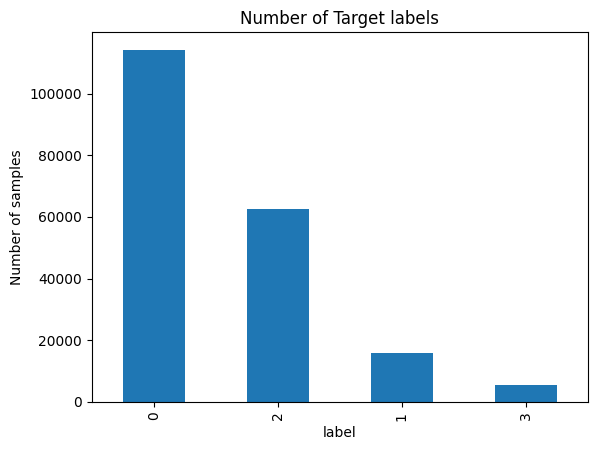

In [50]:
train['label'].value_counts().plot(kind='bar')
plt.title("Number of Target labels")
plt.ylabel("Number of samples")

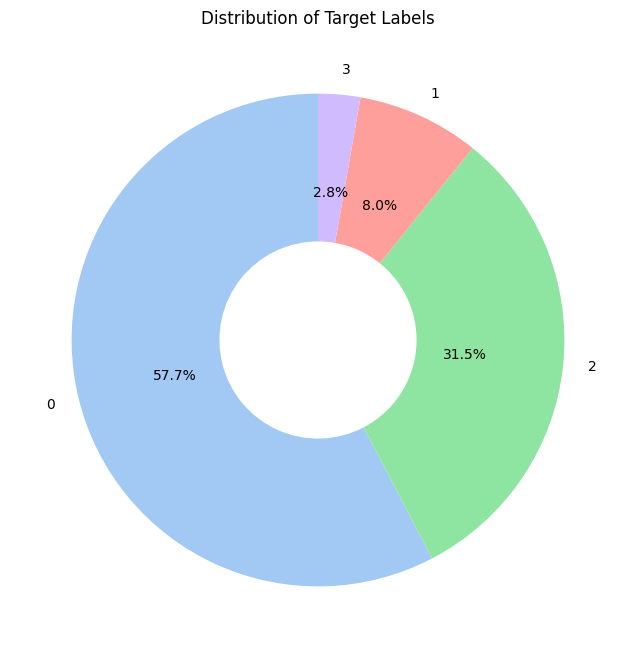

In [51]:
label_distribution = train['label'].value_counts()
plt.figure(figsize=(8,8))
color = sns.color_palette('pastel6')
plt.pie(label_distribution,
        labels=list(label_distribution.index),
        data=train,
        colors=color,
        autopct='%0.1f%%',
        startangle=90,
        wedgeprops=dict(width=0.6))
plt.title("Distribution of Target Labels")
plt.show()

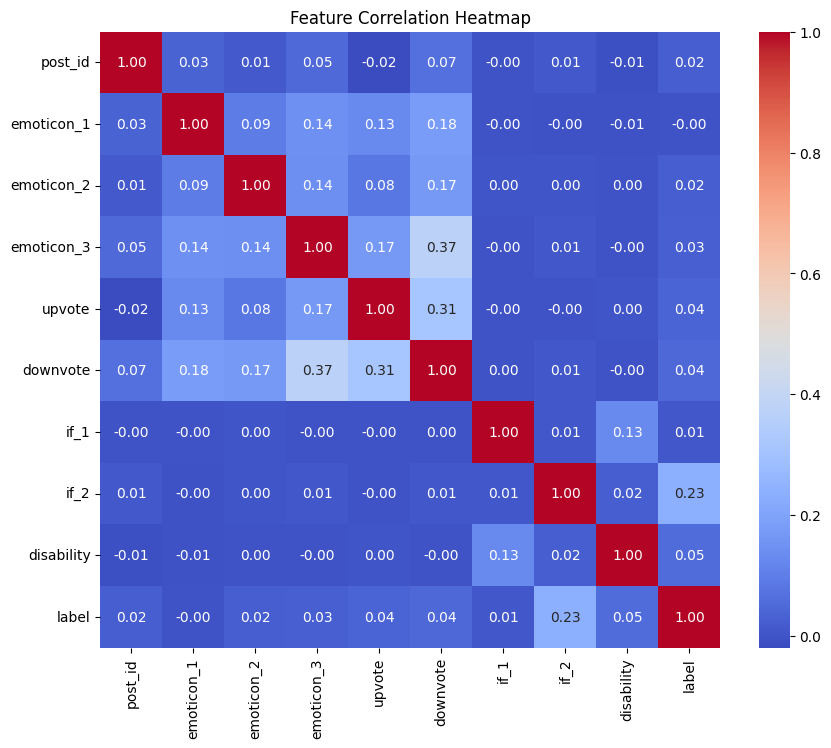

In [52]:
corr = train.corr(numeric_only=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.show()

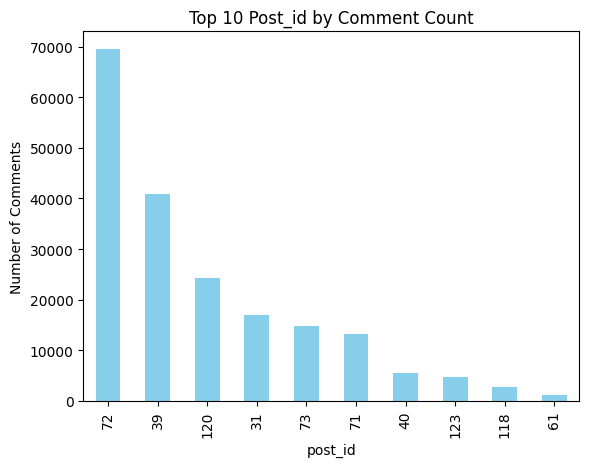

In [53]:
top_posts = train.groupby("post_id").size().sort_values(ascending=False).head(10)
train['comment'] = train["comment"].fillna("")
top_posts.plot(kind="bar",color="skyblue")
plt.title("Top 10 Post_id by Comment Count")
plt.ylabel("Number of Comments")
plt.show()

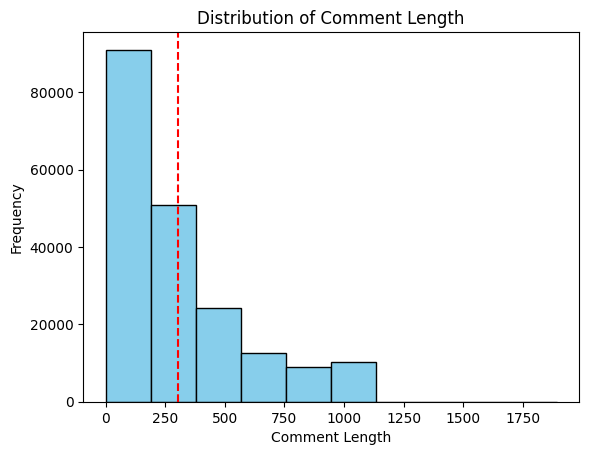

In [54]:
train["comment_length"] = train["comment"].str.len()

plt.hist(train["comment_length"],
         bins=10,
         color='skyblue',
         edgecolor = "black")

# adding line for mean_length 
mean_length = train["comment_length"].mean()
plt.axvline(mean_length,color='red',linestyle='dashed')
plt.title("Distribution of Comment Length")
plt.xlabel("Comment Length")
plt.ylabel("Frequency")
plt.show()

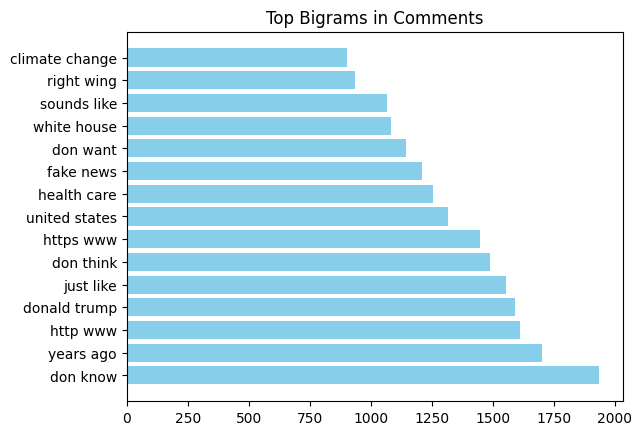

In [55]:
from sklearn.feature_extraction.text import TfidfVectorizer

train['comment'] = train['comment'].fillna("")
vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(2,2), max_features=15)
X = vectorizer.fit_transform(train['comment'])

bigrams = vectorizer.get_feature_names_out()


counts = X.sum(axis=0).A1
#A - convert sparse matrix into dense numpy array 
#A1 - flatten it into 1D array 

bigram_df = pd.DataFrame({"bigram": bigrams, "count": counts}).sort_values(by="count", ascending=False)

plt.barh(bigram_df["bigram"], bigram_df["count"],color="skyblue")
plt.title("Top Bigrams in Comments")
plt.show()

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 4. Feature Engineering and Extraction

</div>

In [65]:
def create_features(df):
    
    df = df.copy()
    
   
    df["created_date"] = pd.to_datetime(df["created_date"], errors="coerce")
    df["hour"] = df["created_date"].dt.hour
    df["day_of_week"] = df["created_date"].dt.dayofweek
    df["month"] = df["created_date"].dt.month
    df["is_weekend"] = df["day_of_week"].isin([5, 6]).astype(int)

    
   
    df["vote_diff"] = df["upvote"] - df["downvote"]
    df["vote_total"] = df["upvote"] + df["downvote"]
    df["upvote_ratio"] = df["upvote"] / (df["vote_total"] + 1)
    df["downvote_ratio"] = df["downvote"] / (df["vote_total"] + 1)
    


    df["comment"] = df["comment"].fillna("")
    
    df["comment_length"] = df["comment"].apply(len)
    df["word_count"] = df["comment"].apply(lambda x: len(x.split()))
    df["exclamation_count"] = df["comment"].apply(lambda x: x.count("!"))
    df["question_count"] = df["comment"].apply(lambda x: x.count("?"))
    
    df["length_vote_interaction"] = df["comment_length"] * df["vote_diff"]
    
    
    
    drop_cols = ["created_date","hour"]
    
    for col in drop_cols:
        if col in df.columns:
            df.drop(columns=col, inplace=True)
    
    
    return df

train = create_features(train)
test = create_features(test)

In [89]:
train["#_count"] = train["comment"].apply(lambda x: x.count("#"))

features = [#"word_count",
            "exclamation_count",
            "question_count",
           "#_count"]

dist = pd.DataFrame(train.groupby("label")[features].sum())

print(dist)

       exclamation_count  question_count  #_count
label                                            
0                  22661           48477      917
1                   3115            8663      120
2                  17181           28117      435
3                   1421            1840       30


Text(0, 0.5, 'punctuation_count')

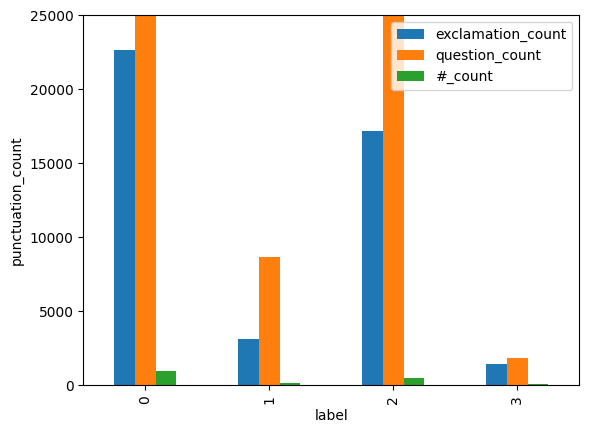

In [92]:
dist.plot(kind='bar')
plt.ylim(0, 25000)
plt.xlabel("label")
plt.ylabel("punctuation_count")


In [19]:
# filling missing categorical value 
cat_cols= ['race','religion','gender']

for col in cat_cols:
    train[col] = train[col].fillna("unknown")
    test[col] = test[col].fillna("unknown")
    

In [20]:
# convert disability to int
train['disability'] = train['disability'].astype(int)
test['disability'] = test['disability'].astype(int)


In [21]:
train['comment'] = train['comment'].fillna("")
test['comment'] = test['comment'].fillna("")

In [22]:
import re
import re

def normalize_text(text):

    # remove all the url and rename to url
    text = re.sub(r'http\S+|www\S+|https\S+', ' URL ', text)
    # removing sapce
    text = re.sub(r'\s+', ' ', text).strip()

    return text

train['comment'] = train['comment'].apply(normalize_text)
test['comment']= test['comment'].apply(normalize_text)

In [23]:
unique_words = set(" ".join(train['comment']).split())
print(len(unique_words))
# no of total unique word in comment

472792


<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# #.Split Data

</div>

In [24]:
# split feature and target
X = train.drop(columns=['label'])
y = train['label']

X_train,X_test, y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42,stratify=y
)

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 4. Data Preprocessing

</div>

In [71]:


text_col = 'comment'

numeric_cols = [
   
    'upvote',
    'downvote',
    'if_1',
    'if_2',
    'emoticon_1',
    'emoticon_2',
    'emoticon_3',
    'disability',
    
    'vote_total',
    'upvote_ratio',
    'downvote_ratio',

    # Text engineered features
    'comment_length',
    'word_count',
    'exclamation_count',
    'question_count'
 ]

categorical_cols = [
     'post_id',
    'race',
    'religion',
    'gender'
]

In [72]:

# word tfidf
word_tfidf = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1,2),
    max_features=23000,
    min_df=3,
    max_df=0.9,
    sublinear_tf=True
)

# char tfidf
char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3,5),
    max_features=15000
)



text_features = FeatureUnion([
    ("word", word_tfidf),
    ("char", char_tfidf)
])

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("log", FunctionTransformer(lambda x: np.log1p(x - x.min()) + 1, validate=False)),  
    ("scaler", StandardScaler())
])

# column transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("text", text_features, "comment"),
        ("num", num_pipeline, numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 5. Model Building & Training

</div>

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model1: Linearsvc

</div>

In [70]:
model1 = Pipeline([
    ('preprocessing', preprocessor),
    ('model',  LinearSVC(max_iter=800,
                                  C=0.5)
     )
     
])
model1

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())...
                                                                   StandardScaler())]),
                                                  ['upvote', 'downvote', 'if_1',
                                                   'if_2', 'emoticon_1',
                                                   'emoticon_2', 'emoticon_3',
                                                   'disability', 'vote_total',
                                                   'upvote_ratio',
                                                   'downvote_ratio',
                                                   'comment_length',
                                                   'word_count',
                                                   'exclamation_count',
                                                   'question_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['post_id', 'race',
                                                   'religion', 'gender'])])),
                ('model', LinearSVC(C=0.5, max_iter=800))])

In [93]:
model1.fit(X_train, y_train)
y_pred = model1.predict(X_train)

print("Training f1 score for model1:", f1_score(y_train, y_pred,average='macro'))



ERROR! Session/line number was not unique in database. History logging moved to new session 29
Training f1 score for model1: 0.9215948126247484


In [94]:
y_pred1 = model1.predict(X_test)
model1_score = f1_score(y_test, y_pred1,average='macro')
model1_score

0.7953398032730558

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model2: LogisticRegression

</div>

In [73]:
model2 = Pipeline([
    ('preprocessing', preprocessor),
    ('model2',LogisticRegression(max_iter=1000,
                      class_weight='balanced',
                      C=1))
     
])
model2

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer())...
                                                   'if_2', 'emoticon_1',
                                                   'emoticon_2', 'emoticon_3',
                                                   'disability', 'vote_total',
                                                   'upvote_ratio',
                                                   'downvote_ratio',
                                                   'comment_length',
                                                   'word_count',
                                                   'exclamation_count',
                                                   'question_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['post_id', 'race',
                                                   'religion', 'gender'])])),
                ('model2',
                 LogisticRegression(C=1, class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [75]:
model2.fit(X_train, y_train)
y_pred_lr_train = model2.predict(X_train)
print("Logistic Regression f1_score for train:", f1_score(y_train, y_pred_lr_train,average='macro'))

Logistic Regression f1_score for train: 0.8833032237112792


In [76]:
y_pred_lr = model2.predict(X_test)
model2_score = f1_score(y_test, y_pred_lr,average='macro')
model2_score

0.8004997526676128

In [77]:
print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.98      0.93      0.96     22835
           1       0.68      0.85      0.76      3183
           2       0.88      0.87      0.87     12488
           3       0.51      0.77      0.61      1094

    accuracy                           0.90     39600
   macro avg       0.76      0.86      0.80     39600
weighted avg       0.91      0.90      0.90     39600



In [78]:
# confusion matrix 
confusion_matrix(y_test, y_pred_lr)

array([[21268,   358,   952,   257],
       [   19,  2708,   355,   101],
       [  366,   823, 10846,   453],
       [   18,    72,   161,   843]])

In [81]:
# Get preprocessing step from pipeline
preprocessor = model2.named_steps["preprocessing"]

# Get text transformers
text_transformer = preprocessor.named_transformers_["text"]

# extract word and character tfidf vectorizers
word_vectorizer = text_transformer.transformer_list[0][1]
char_vectorizer = text_transformer.transformer_list[1][1]

# Get feature names
word_features = word_vectorizer.get_feature_names_out()
char_features = char_vectorizer.get_feature_names_out()

# Numerical and categorical feature names
num_features = numeric_cols
cat_features = preprocessor.named_transformers_["cat"].get_feature_names_out()


all_features = list(word_features) + list(char_features) + list(num_features) + list(cat_features)
coef = model2.named_steps["model2"].coef_[0] ##
feature_coef = list(zip(coef, all_features))


feature_coef_sorted = sorted(feature_coef)


top_negative = feature_coef_sorted[:10]

top_positive = feature_coef_sorted[-10:]

print("Top Positive Features:")
print(top_positive)
print("Top Negative Features:")
print(top_negative)

Top Positive Features:
[(np.float64(0.9031021102771999), 'thank you'), (np.float64(0.9226661762816833), 'cool'), (np.float64(0.9299131612826447), 'fooled'), (np.float64(0.9850806985824425), 'kill people'), (np.float64(1.0271037313360611), 'walker'), (np.float64(1.0333229112329338), 'lose'), (np.float64(1.0393655407954685), 'not'), (np.float64(1.1116428163167391), 'these are'), (np.float64(1.3613599430130017), '!! '), (np.float64(2.0072383088145673), 'url')]

Top Negative Features:
[(np.float64(-3.0929355871009636), 'if_2'), (np.float64(-2.928427095324739), 'stupid'), (np.float64(-2.871103832301776), 'dumb'), (np.float64(-2.6112910021729023), 'pig'), (np.float64(-2.4614840242580014), 'loser'), (np.float64(-2.4400976740802003), 'pathetic'), (np.float64(-2.415588072605367), 'fools'), (np.float64(-2.4086771857668205), 'fool'), (np.float64(-2.13773316604454), 'ignorant'), (np.float64(-2.1031087104131436), 'idiot')]


<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model3 -Naive Bayes

</div>

In [ ]:
from sklearn.preprocessing import MinMaxScaler
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("log", FunctionTransformer(lambda x: np.log1p(x - x.min()) + 1, validate=False)),  
    ("scaler", MinMaxScaler())
])

# column transformer
preprocessor3 = ColumnTransformer(
    transformers=[
        ("text", text_features, "comment"),
        ("num", num_pipeline, numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

from sklearn.naive_bayes import MultinomialNB
model3 = Pipeline(
    [
        ('preprocessing' , preprocessor3),
        ('model',MultinomialNB(alpha=0.1))
    ]
)
model3

In [99]:
model3.fit(X_train, y_train)
y_pred = model3.predict(X_train)

print("Training f1 score for model3:", f1_score(y_train, y_pred,average='macro'))

Training f1 score for model3: 0.6162136292649951


In [100]:
y_pred3 = model3.predict(X_test)
model3_score =f1_score(y_test, y_pred3,average='macro')
model3_score

0.5976169278449488

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 6. Hyperparameter Tuning

</div>

In [ ]:
param_dist = {
    
    "model__C" : [0.5,1],
    "model__max_iter": [800,1000,1200]
}


from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(estimator=model1, param_grid=param_dist, cv=3, scoring='f1', n_jobs=-1)

grid.fit(X_train, y_train)

print(grid.best_params_)


{'model__C': 0.5, 'model__max_iter': 800}

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model2: Logistic Regression

</div>

In [ ]:
param_dist = {
     "model2__C" : [0.5,1,2],
    "model2__max_iter": [500,1000,12000]
}
grid2 = RandomizedSearchCV(estimator=model2,
                    param_distributions=param_dist,
                    cv=3,
                    n_iter = 5,
                    scoring='f1')

grid2.fit(X_train, y_train)

print(grid2.best_params_)

{'model2__max_iter': 1000, 'model2__C': 1}

<div style="
border-left:6px solid #3cb371;
padding:10px;
background:#f8fffb;
font-size:10px;
font-weight:bold;
color:#2f6f4f;
width:80%">

## Model3:navie Bayes

</div>

In [102]:
param_dist = {
    "model__alpha" : [0.01,0.1]
}

In [103]:
grid3 = GridSearchCV(estimator=model3,
                    param_grid=param_dist,
                    cv=3,
                    scoring='f1')

grid3.fit(X_train, y_train)

print(grid3.best_params_)

{'model__alpha': 0.01}
nan


<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 7.Best model and Analysis

</div>

In [ ]:
names = ['linear svc','logistic regression','Naive Bayes']
score = [model1_score, model2_score, model3_score]

plt.figure(figsize=(10,8))
graph = plt.barh(names,score)
plt.xlabel('f1_score')
plt.ylabel('Models')

graph[0].set_color('lightgreen')
graph[1].set_color('lightblure')
graph[2].set_color('lightbrown')

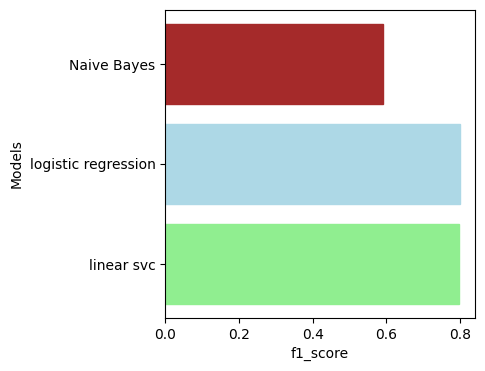

<div style="border-left:8px solid #2e8b57;padding:12px;background:#f4fff7;font-size:15px;font-weight:bold;color:#2e8b57;">

# 8.Submission

</div>

In [32]:
final_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        C=2,
        max_iter=1200,
        class_weight="balanced"
    ))
])
final_model

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('text',
                                                  FeatureUnion(transformer_list=[('word',
                                                                                  TfidfVectorizer(max_df=0.9,
                                                                                                  max_features=23000,
                                                                                                  min_df=3,
                                                                                                  ngram_range=(1,
                                                                                                               2),
                                                                                                  sublinear_tf=True)),
                                                                                 ('char',
                                                                                  TfidfVectorizer(analyzer='char_wb',
                                                                                                  max_features=15000,
                                                                                                  ngram_range=(3,
                                                                                                               5)))]),
                                                  'comment'),
                                                 ('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer()),...
                                                  ['upvote', 'downvote', 'if_1',
                                                   'if_2', 'emoticon_1',
                                                   'emoticon_2', 'emoticon_3',
                                                   'disability', 'vote_total',
                                                   'upvote_ratio',
                                                   'downvote_ratio',
                                                   'comment_length',
                                                   'word_count',
                                                   'exclamation_count',
                                                   'question_count']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['post_id', 'race',
                                                   'religion', 'gender'])])),
                ('classifier',
                 LogisticRegression(C=2, class_weight='balanced',
                                    max_iter=1100))])

In [ ]:
final_model.fit(X, y)

In [ ]:
prediction = final_model.predict(test)

In [ ]:
submission = pd.DataFrame({
    "ID": sample["ID"],
    "label": prediction
})

submission.to_csv("submission.csv", index=False)
submission.head()

In [ ]:
submission['label'].value_counts()